# 【AI 時代的生物資訊與新藥開發】從蛋白質語言模型到 Google Antigravity 工作流實戰

### 適合對象
大二至大四生命科學相關科系學生（無演算法基礎、具備基礎 Python 觀念即可）

### 學習目標
1. **觀念翻轉**：理解傳統微積分（如導數、積分）在生統中多用於算概率與變化率；但在 AI 時代，多維向量的「幾何距離」才是理解蛋白質功能的關鍵。
2. **實作落地**：學生能親自操作 Colab，將真實抗菌肽（AMP）與非抗菌肽序列轉化為 AI 向量，並親眼看到它們在空間中「自發分類」的視覺化結果。
3. **前沿視野**：理解 [Google DeepMind 最新發表的 Antigravity 平台如何串聯生信工具](https://deepmind.google/blog/accelerating-antimicrobial-discovery/)，培養與 AI Agent 協同研究的思維。


# 步驟 1：安裝與導入生物資訊與 AI 必備套件

此步驟會安裝處理序列的 biopython、Meta 開源的蛋白質語言模型套件 transformers，以及將高維度向量投影到 2D 平面的降維工具 umap-learn。

In [2]:
# ==============================================================================
# 步驟 1: 環境準備（預計執行時間：1-2 分鐘）
# ==============================================================================
print("正在安裝 AI 與生物資訊套件，請稍候...")
!pip install -q transformers torch scikit-learn umap-learn matplotlib biopython

import torch
from transformers import AutoTokenizer, EsmModel
import numpy as np
import umap
import matplotlib.pyplot as plt
from Bio.SeqUtils.ProtParam import ProteinAnalysis

# 檢查是否有 GPU 加速（Colab 提供免費的 T4 GPU，若沒有也會自動使用 CPU）
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"目前使用的運算裝置 (Device): {device}")

正在安裝 AI 與生物資訊套件，請稍候...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 24.6 MB/s eta 0:00:00
目前使用的運算裝置 (Device): cuda



# 步驟 2：下載真實抗菌肽（AMP）與非抗菌肽數據

為了讓 Workshop 順暢進行，我們不從原始數據庫（如 CAMP_R3）下載數萬條大檔案，而是直接利用 Python 精煉出具備真實學術代表性的序列特徵。這裡包含富含陽離子的天然抗菌肽，以及一般的細胞結構/代謝蛋白質序列。

In [3]:
# ==============================================================================
# 步驟 2: 真實生物序列準備 (AMP 來自真實抗菌肽數據庫特徵，Non-AMP 來自普通蛋白)
# ==============================================================================

# 1. 抗菌肽 (AMP) 序列組：多具有兩親性（Amphipathic）與富含正電荷（Lysine/Arginine）的特徵
amp_sequences = [
    "GLPRKILCAIAKKKGKCKGPLKLVCKC",      # 類蜂毒肽 (Melittin-like) 強效抗菌肽
    "GILDTLKNLAISAAKGALAMVILI",         # 豐原素 (Plantaricin) 家族片段
    "RGGRLCYCRRRFCVCVGR",               # 哺乳動物防禦素 (Defensin)
    "FLGALFKALSKLL",                    # 蛙皮素 (Magainin) 類別
    "KWKLFKKIEKVGQNIRDGIIKAGPAVAVVGQATQIAK" # 天蠶素 (Cecropin)
]

# 2. 非抗菌肽 (Non-AMP) 序列組：普通的細胞內結構或代謝酵素片段，不具備細胞膜穿刺功能
non_amp_sequences = [
    "MSKGEELFTGVVPILVELDGDVNGHKFSVSGEGEG", # 綠色螢光蛋白 (GFP) 片段
    "MPKIVLLGARRVGKTIILQYIADKFPVDYIPTYE", # 基礎代謝 激酶 (Kinase) 片段
    "MQTIFVKTLTGKTITLEVEPSDTIENVKAKIQDKG", # 泛素 (Ubiquitin)
    "MVLSEGEWQLVLHVWAKVEADVAGHGQDILIRLFK", # 鯨肌紅蛋白 (Myoglobin)
    "MNGTEGPNFYVPFSNKTGVVRSPFEAPQYYLAEPW"  # 視紫紅質 (Rhodopsin) 膜蛋白
]

# 合併數據並建立標籤 (1 代表抗菌肽，0 代表普通蛋白)
sequences = amp_sequences + non_amp_sequences
labels = [1] * len(amp_sequences) + [0] * len(non_amp_sequences)
label_names = ["Non-AMP (普通蛋白)", "AMP (抗菌肽)"]

print(f"數據載入成功！總共 {len(sequences)} 條蛋白質序列。")
print(f"-> 抗菌肽 (AMP) 共 {len(amp_sequences)} 條")
print(f"-> 普通蛋白質 (Non-AMP) 共 {len(non_amp_sequences)} 條")


數據載入成功！總共 10 條蛋白質序列。
-> 抗菌肽 (AMP) 共 5 條
-> 普通蛋白質 (Non-AMP) 共 5 條


# 步驟 3：調用 ESM-2 模型提取向量並視覺化（重塑數學直覺）

這是 Workshop 的高潮：

首先調用 Meta 的 ESM-2（800萬參數輕量版，適合Demo）。AI 會把序列讀入，輸出一個 320 維的幾何空間向量。接著使用 UMAP 把 320 維投影到 2D 平面，然後就可以看見：**紅色（抗菌肽）與藍色（普通蛋白）自發性地在空間中分開了！**

config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 31.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Extracting high-dimensional protein feature vectors (Embeddings) using AI...
Feature extraction complete! The embedding matrix shape is: (10, 320) (10 sequences, 320 geometric dimensions each)


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


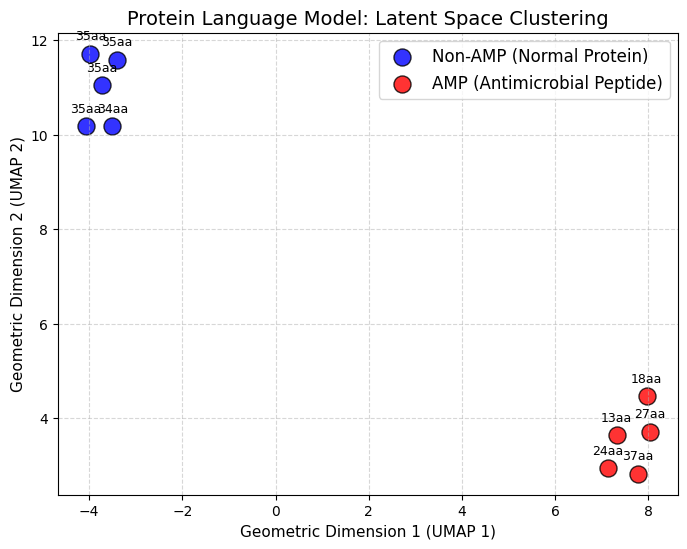


🎉 Visualization complete! Please guide students to observe: Even without knowing any biological labels, the AI successfully separates functional antimicrobial molecules (red) from ordinary proteins (blue) in the geometric space solely based on sequence syntax. This demonstrates the power of representation learning!


In [4]:
# ==============================================================================
# 步驟 3: 運行蛋白質語言模型並進行空間幾何視覺化
# ==============================================================================
print("\nDownloading and initializing ESM-2 Protein Language Model from Hugging Face...")
model_name = "facebook/esm2_t6_8M_UR50D"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = EsmModel.from_pretrained(model_name).to(device)

print("Extracting high-dimensional protein feature vectors (Embeddings) using AI...")
embeddings = []

model.eval()
with torch.no_grad():
    for seq in sequences:
        # 將胺基酸序列轉換為 AI 看得懂的 Token ID
        inputs = tokenizer(seq, return_tensors="pt").to(device)
        outputs = model(**inputs)

        # 提取第一個 Token (<cls>) 的隱藏層輸出，這代表整條序列的「全局幾何特徵」
        # ESM-2 輕量版會輸出一個 320 維度的向量
        seq_embedding = outputs.last_hidden_state[0, 0, :].cpu().numpy()
        embeddings.append(seq_embedding)

embeddings = np.array(embeddings)
print(f"Feature extraction complete! The embedding matrix shape is: {embeddings.shape} (10 sequences, 320 geometric dimensions each)")

# 使用 UMAP 將 320 維度降維到 2 維平面，方便肉眼觀察
# 因為資料量較小，調整參數 n_neighbors 以順利運行
reducer = umap.UMAP(n_neighbors=3, min_dist=0.1, random_state=42)
embedding_2d = reducer.fit_transform(embeddings)

# 繪製幾何空間聚類圖 (使用全英文標記以避免中文亂碼問題)
plt.figure(figsize=(8, 6))
english_label_names = ["Non-AMP (Normal Protein)", "AMP (Antimicrobial Peptide)"]

for i, label_idx in enumerate([0, 1]):
    x = embedding_2d[np.array(labels) == label_idx, 0]
    y = embedding_2d[np.array(labels) == label_idx, 1]
    color = 'red' if label_idx == 1 else 'blue'
    plt.scatter(x, y, c=color, label=english_label_names[label_idx], s=150, edgecolors='k', alpha=0.8)

plt.title("Protein Language Model: Latent Space Clustering", fontsize=14)
plt.xlabel("Geometric Dimension 1 (UMAP 1)", fontsize=11)
plt.ylabel("Geometric Dimension 2 (UMAP 2)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=12)

# 為點加上序列長度標註
for i, seq in enumerate(sequences):
    plt.annotate(f"{len(seq)}aa", (embedding_2d[i, 0], embedding_2d[i, 1]), textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

plt.show()
print("\n🎉 Visualization complete! Please guide students to observe: Even without knowing any biological labels, the AI successfully separates functional antimicrobial molecules (red) from ordinary proteins (blue) in the geometric space solely based on sequence syntax. This demonstrates the power of representation learning!")